# Analisis ISPA di Indonesia 2026

**Infeksi Saluran Pernapasan Akut (ISPA)**: kasus melonjak pada musim kemarau 2026,
bersamaan dengan kebakaran hutan dan lahan (karhutla) dan memburuknya kualitas udara.
Analisis ini menjawab: seberapa besar lonjakannya, di mana kasus terbanyak,
siapa yang paling terdampak, dan apa kaitannya dengan karhutla dan kualitas udara.

> **PENTING — Sifat data: KOMPILASI.** Dataset ini dikompilasi dari angka-angka
> resmi yang dipublikasikan (rilis pers Kemenkes dan laporan yang mengutipnya).
> Tidak ada file CSV mentah ISPA yang bisa diunduh dari data.go.id atau Jakarta
> Open Data saat proyek ini dibuat (dicek 16 Oktober 2026). Setiap angka dicatat
> bersama sumber dan tanggalnya di `data/SOURCES.md`. Tidak ada angka yang dikarang.

> **DUA SERI YANG TIDAK DICAMPUR.** Analisis ini memakai dua seri terpisah:
> (1) **seri nasional SKDR** — laporan ISPA seluruh Indonesia (total 14.088.945
> laporan s.d. minggu ke-38 2026); (2) **seri pemantauan karhutla** — pemantauan
> khusus di 63 kabupaten/kota, 7 provinsi (283.270 kasus, 18 Agt–13 Okt 2026).
> Kedua seri memiliki cakupan dan tanggal berbeda dan **tidak pernah** dijumlahkan
> atau digabung dalam satu chart.

## Pertanyaan analisis

1. Seberapa besar total laporan ISPA nasional 2026 dan bagaimana tren mingguannya?
2. Provinsi mana yang mencatat kasus terbanyak — secara absolut dan per kapita?
3. Seberapa terkonsentrasi kasus di Pulau Jawa?
4. Pada seri karhutla: berapa kasusnya, di provinsi mana, dan siapa yang terdampak (usia)?
5. Bagaimana kondisi kualitas udara di wilayah terdampak?
6. Bagaimana pola bulanan ISPA di Jakarta sebagai studi kota?


In [1]:
import sqlite3
import pandas as pd
from IPython.display import Image, display

con = sqlite3.connect("data/ispa_indonesia.db")

def q(sql):
    return pd.read_sql(sql, con)


## A. Gambaran nasional (seri SKDR)

Total laporan ISPA nasional 2026 mencapai **14.088.945 laporan** hingga minggu
epidemiologi ke-38, menurut Situation Report Kemenkes. Laporan mingguan naik dari
**lebih dari 400.000 per minggu** pada awal musim kemarau (minggu 27–31) menjadi
**sekitar 420.000 per minggu** pada puncaknya (minggu 32–37) — naik 5,0%.


             periode minggu_epidemiologi laporan_per_minggu
  Awal musim kemarau               27-31             400000
Puncak musim kemarau               32-37             420000

Kenaikan awal -> puncak musim kemarau: 5.0 %


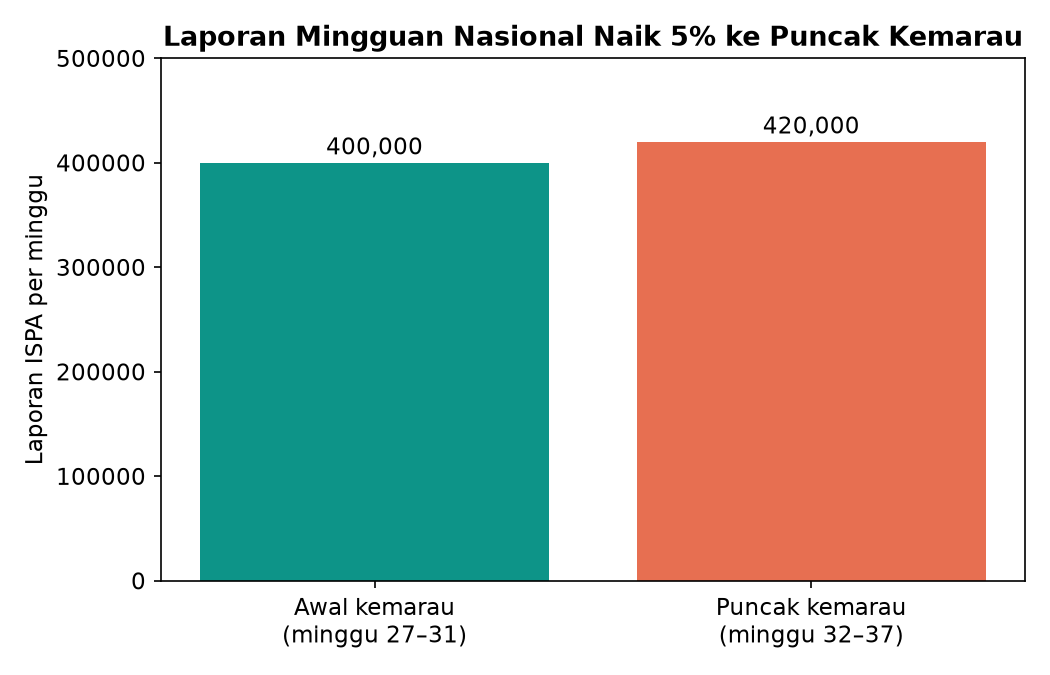

In [2]:
print(q("SELECT * FROM mingguan_nasional")[['periode', 'minggu_epidemiologi', 'laporan_per_minggu']].to_string(index=False))
print()
print("Kenaikan awal -> puncak musim kemarau:",
      q("SELECT ROUND(100.0*(420000-400000)/400000, 1) AS persen").iloc[0, 0], "%")
display(Image("charts/09_mingguan_nasional.png"))


## B. 10 provinsi dengan kasus terbanyak (seri SKDR, absolut)

Jawa Barat mencatat laporan terbanyak (2.533.888), diikuti Jawa Tengah (2.358.930),
DKI Jakarta (1.600.814), dan Jawa Timur (1.374.373). Keempat provinsi ini saja
menyumbang **55,8%** dari seluruh laporan nasional. Catatan: angka 4 provinsi
teratas dikutip eksak dari teks rilis; peringkat 5–10 dibaca dari grafik (dibulatkan).


           provinsi   kasus  persen_nasional
         Jawa Barat 2533888            17.98
        Jawa Tengah 2358930            16.74
        DKI Jakarta 1600814            11.36
         Jawa Timur 1374373             9.75
             Banten  832030             5.91
   Sulawesi Selatan  408770             2.90
      DI Yogyakarta  388380             2.76
     Sumatera Utara  364050             2.58
     Sumatera Barat  337200             2.39
Nusa Tenggara Barat  331950             2.36


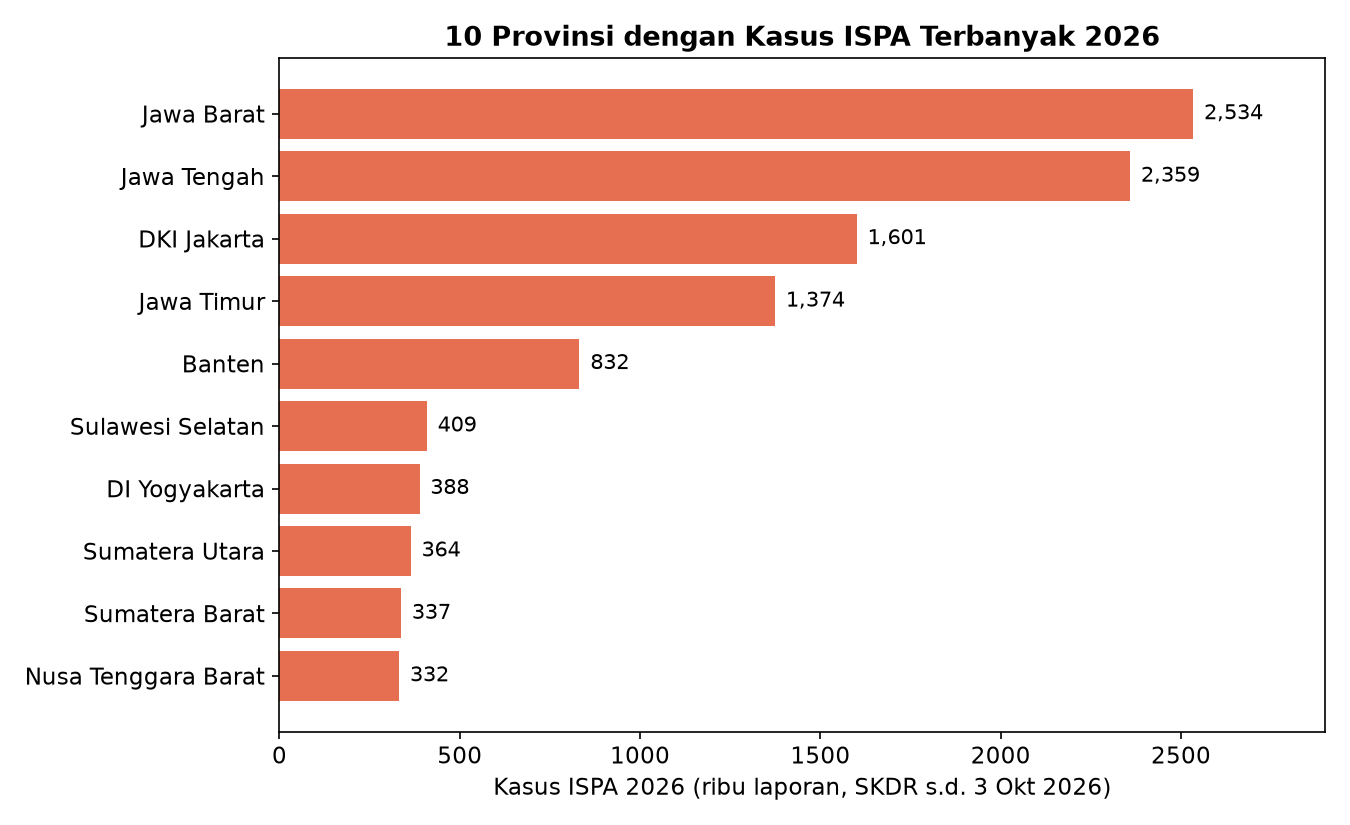

In [3]:
print(q("""SELECT provinsi, CAST(kasus_skdr_2026 AS INTEGER) AS kasus,
       ROUND(100.0 * CAST(kasus_skdr_2026 AS INTEGER) / 14088945, 2) AS persen_nasional
       FROM skdr_provinsi ORDER BY kasus DESC""").to_string(index=False))
display(Image("charts/01_top10_absolut.png"))


## C. Konsentrasi: 10 provinsi teratas = 74,7% laporan nasional

Sepuluh provinsi teratas mencatat 10.530.385 laporan — **74,7%** dari total nasional.
Sisanya (28 provinsi lain) hanya 25,3%. Beban ISPA sangat terkonsentrasi di
provinsi-provinsi besar.


 total_top10  persen_nasional
    10530385             74.7


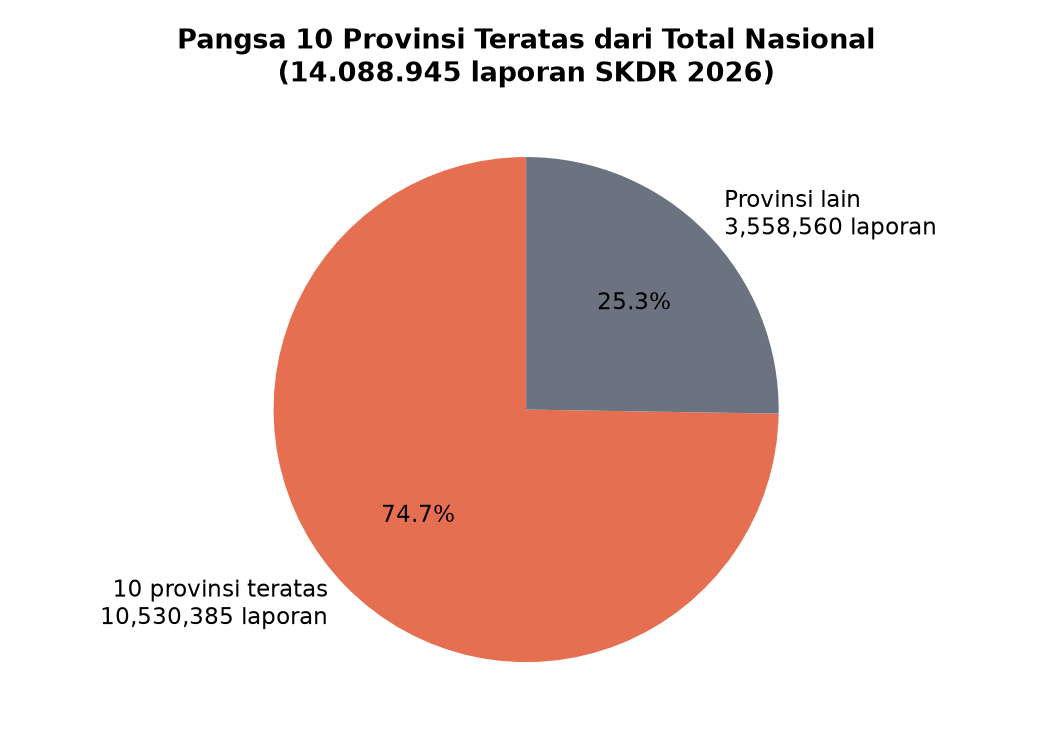

In [4]:
print(q("""SELECT SUM(CAST(kasus_skdr_2026 AS INTEGER)) AS total_top10,
       ROUND(100.0 * SUM(CAST(kasus_skdr_2026 AS INTEGER)) / 14088945, 1) AS persen_nasional
       FROM skdr_provinsi""").to_string(index=False))
display(Image("charts/02_pangsa_top10.png"))


## D. Per kapita: Jakarta bebannya paling berat

Angka absolut menipu: provinsi berpenduduk besar otomatis mencatat kasus lebih banyak.
Setelah dibagi populasi (BPS 2026), **DKI Jakarta mencatat 150,0 kasus per 1.000
penduduk** — sekitar 3 kali Jawa Barat (49,5) dan 2,3 kali Banten (65,8).
Jakarta mencatat kasus lebih banyak daripada Jawa Timur (rasio 1,16x) padahal
penduduknya hanya seperempat Jawa Timur. Tiga provinsi (DIY, Sumbar, NTB)
dikeluarkan dari peringkat per kapita karena tidak ada angka populasi satu vintage
yang terverifikasi — nilai absolutnya tetap ditampilkan di Bagian B.


        provinsi   kasus  populasi  kasus_per_1000
     DKI Jakarta 1600814  10670000           150.0
          Banten  832030  12640000            65.8
     Jawa Tengah 2358930  38560000            61.2
      Jawa Barat 2533888  51160000            49.5
Sulawesi Selatan  408770   9660000            42.3
      Jawa Timur 1374373  42350000            32.5
  Sumatera Utara  364050  15980000            22.8


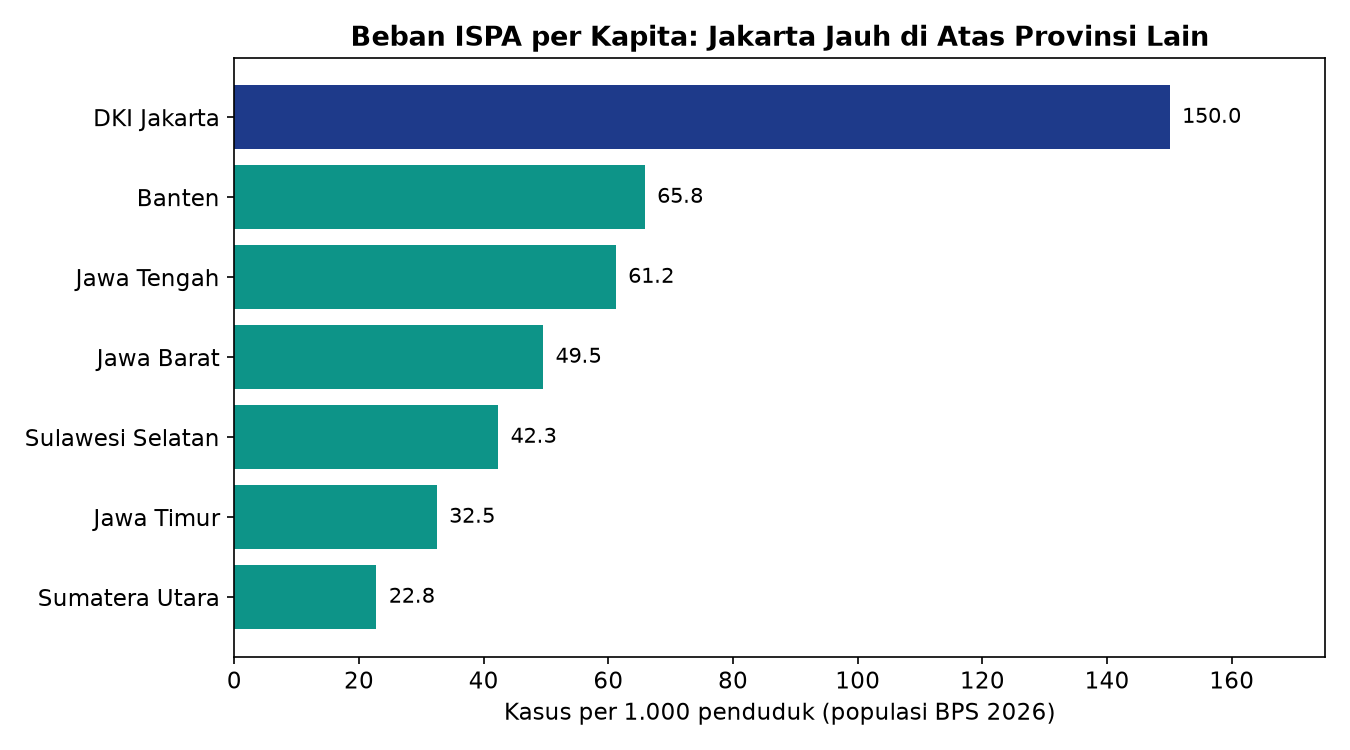

In [5]:
print(q("""SELECT provinsi, CAST(kasus_skdr_2026 AS INTEGER) AS kasus,
       CAST(populasi_2026 AS INTEGER) AS populasi,
       ROUND(1000.0 * CAST(kasus_skdr_2026 AS INTEGER) / CAST(populasi_2026 AS INTEGER), 1) AS kasus_per_1000
       FROM skdr_provinsi WHERE populasi_2026 != '' ORDER BY kasus_per_1000 DESC""").to_string(index=False))
display(Image("charts/03_per_kapita.png"))


## E. Dominasi Pulau Jawa

Dari 10 provinsi teratas, **86,3%** laporannya berasal dari Pulau Jawa
(Jabar, Jateng, Jakarta, Jatim, Banten, DIY). Ini sekaligus peringatan metodologis:
dominasi Jawa tidak otomatis berarti Jawa paling parah terdampak karhutla —
jumlah penduduk, cakupan fasilitas kesehatan, dan kelengkapan pelaporan turut
memengaruhi jumlah kasus yang tercatat (Kemenkes, dikutip GoodStats).


In [6]:
print(q("""SELECT CASE WHEN provinsi IN ('Jawa Barat','Jawa Tengah','DKI Jakarta','Jawa Timur','Banten','DI Yogyakarta')
            THEN 'Pulau Jawa' ELSE 'Luar Jawa' END AS wilayah,
       SUM(CAST(kasus_skdr_2026 AS INTEGER)) AS kasus,
       ROUND(100.0 * SUM(CAST(kasus_skdr_2026 AS INTEGER)) / 10530385, 1) AS persen_top10
       FROM skdr_provinsi GROUP BY wilayah""").to_string(index=False))


   wilayah   kasus  persen_top10
 Luar Jawa 1441970          13.7
Pulau Jawa 9088415          86.3


## F. Seri karhutla: 283.270 kasus, hampir 1 dari 4 adalah balita

Berpindah ke seri **pemantauan karhutla** (terpisah dari seri nasional):
283.270 kasus ISPA tercatat di 63 kabupaten/kota, 7 provinsi, pada 18 Agustus–
13 Oktober 2026. Dari jumlah itu **63.711 kasus (22,5%) dialami balita (0–5 tahun)**
dan 219.559 kasus (77,5%) usia di atas 5 tahun. Rata-rata **4.496 kasus per
kabupaten/kota** terdampak.


 total balita usia_diatas_5  persen_balita
283270  63711        219559           22.5
Rata-rata kasus per kab/kota: 4496.0


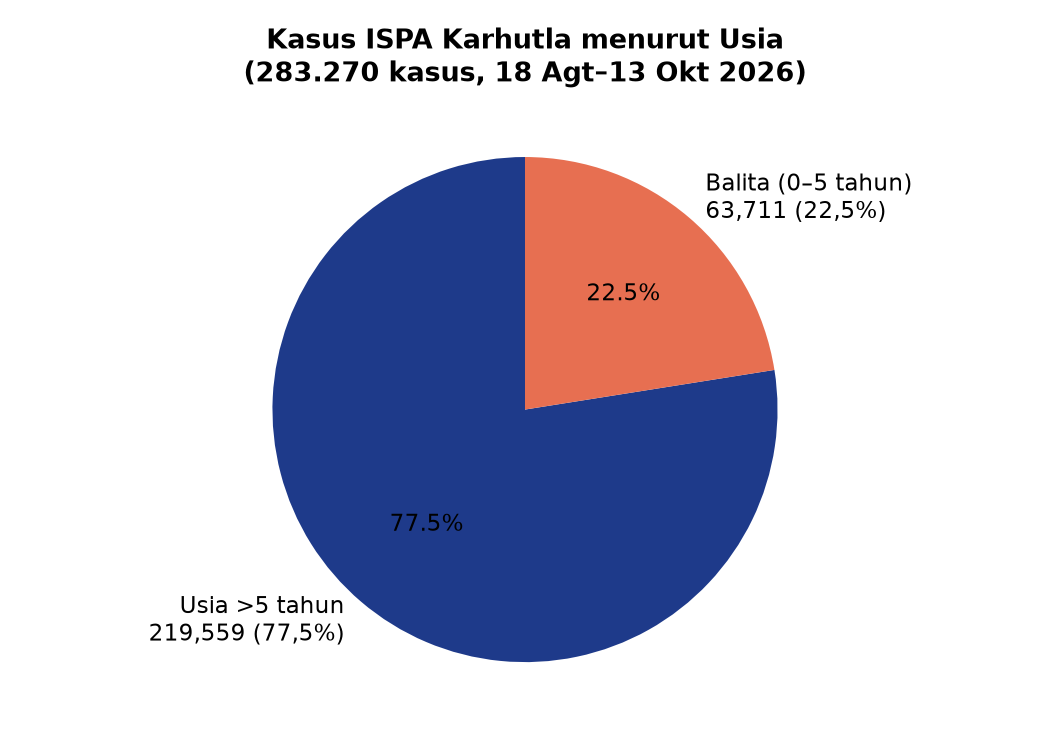

In [7]:
print(q("""SELECT kasus_kumulatif AS total, balita_0_5_tahun AS balita,
       usia_diatas_5_tahun AS usia_diatas_5,
       ROUND(100.0 * CAST(balita_0_5_tahun AS INTEGER) / CAST(kasus_kumulatif AS INTEGER), 1) AS persen_balita
       FROM karhutla_series WHERE tanggal = '2026-10-13'""").to_string(index=False))
print("Rata-rata kasus per kab/kota:", q("SELECT ROUND(283270.0/63, 0) AS r").iloc[0, 0])
display(Image("charts/05_karhutla_usia.png"))


## G. Seri karhutla: dua provinsi menyumbang lebih dari separuh

Kalimantan Selatan (74.636 kasus, 26,3%) dan Sumatera Selatan (74.458 kasus, 26,3%)
bersama-sama menyumbang **52,6%** dari seluruh kasus seri karhutla. Selisih keduanya
hanya **178 kasus (0,24%)** — praktis berimbang. Lima provinsi terdampak lainnya
(Kalbar, Kalteng, Kaltim, Jambi, Riau) digabung mencatat 134.176 kasus (47,4%);
rincian per provinsinya tidak dipublikasikan.


                  provinsi  kasus  persen
5 provinsi lain (gabungan) 134176    47.4
        Kalimantan Selatan  74636    26.3
          Sumatera Selatan  74458    26.3
Selisih Kalsel - Sumsel: 178 kasus


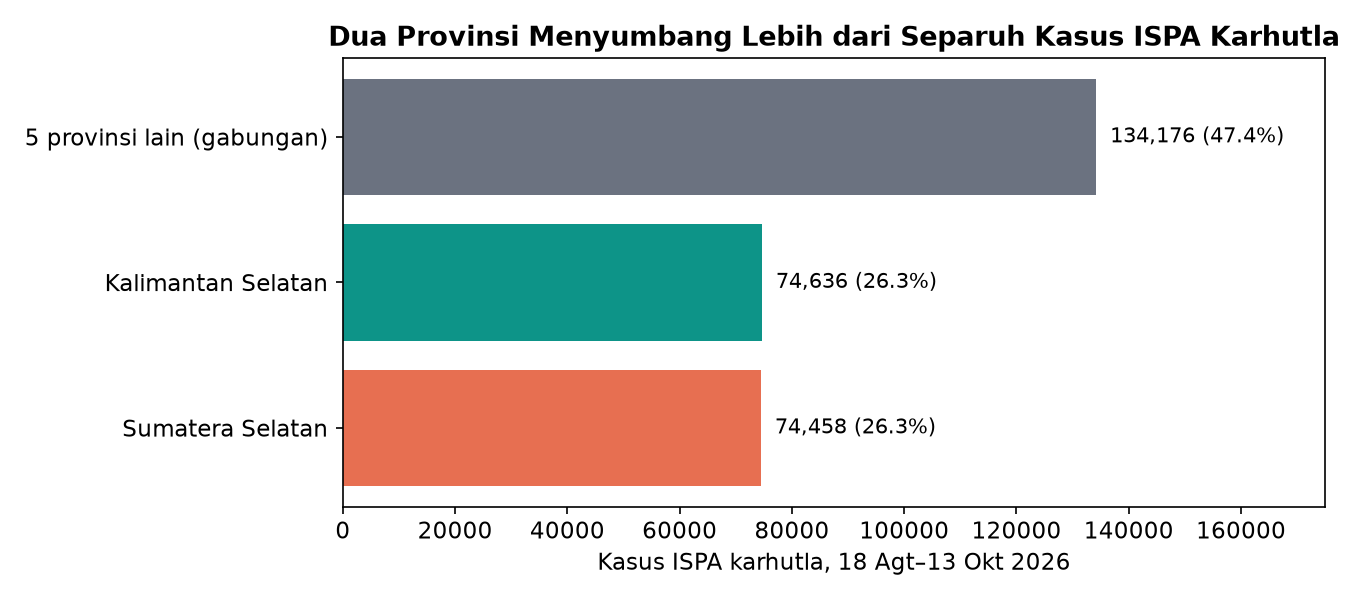

In [8]:
print(q("""SELECT provinsi, CAST(kasus_karhutla_18agt_13okt_2026 AS INTEGER) AS kasus,
       ROUND(100.0 * CAST(kasus_karhutla_18agt_13okt_2026 AS INTEGER) / 283270, 1) AS persen
       FROM karhutla_provinsi ORDER BY kasus DESC""").to_string(index=False))
print("Selisih Kalsel - Sumsel:", q("SELECT 74636 - 74458 AS s").iloc[0, 0], "kasus")
display(Image("charts/04_karhutla_provinsi.png"))


## H. Seri karhutla: pertumbuhan 21 kali lipat dalam 7 minggu

Kasus kumulatif seri karhutla naik dari **13.449 (27 Agustus)** menjadi **174.694
(21 September)** dan **283.270 (13 Oktober)** — **21,1 kali lipat** dalam 7 minggu.
Pada 13 Oktober saja tercatat 3.897 kasus baru harian. Sementara itu porsi balita
stabil: 23,1% pada 21 September menjadi 22,5% pada 13 Oktober — hampir 1 dari
4 kasus karhutla adalah balita pada kedua titik waktu.


   tanggal  kumulatif
2026-08-27      13449
2026-09-21     174694
2026-10-13     283270
Faktor pertumbuhan 27 Agt -> 13 Okt: 21.1 kali lipat


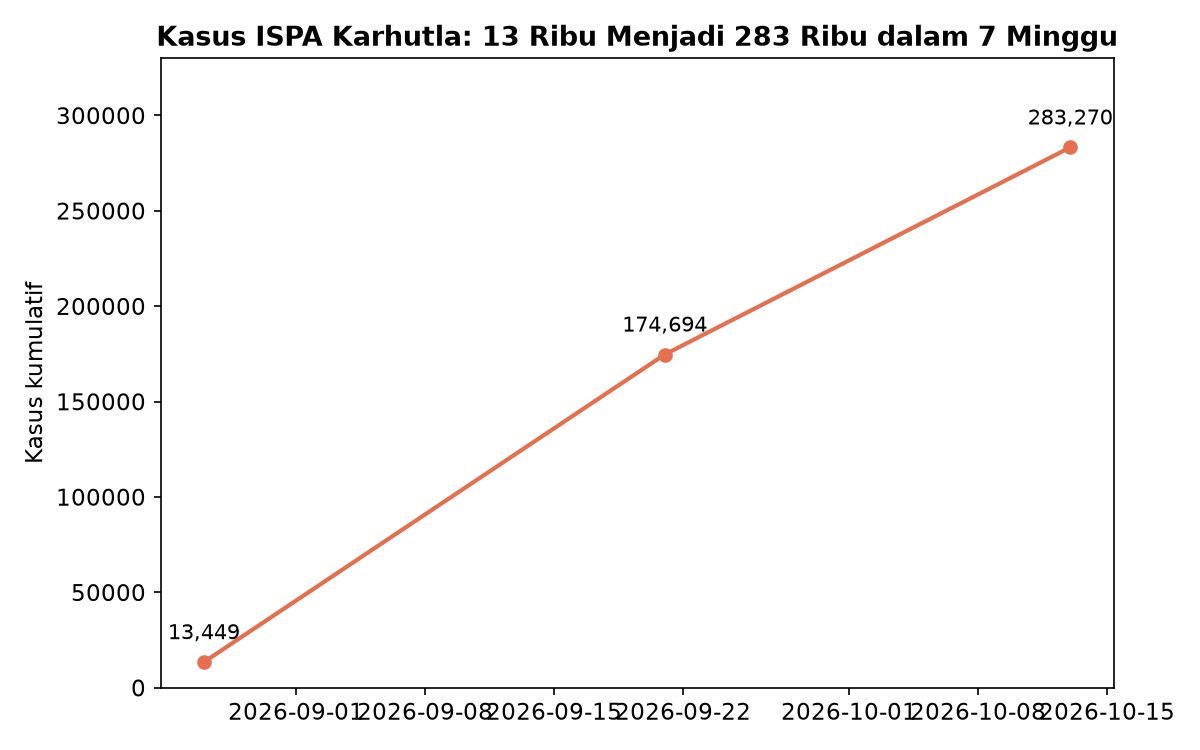

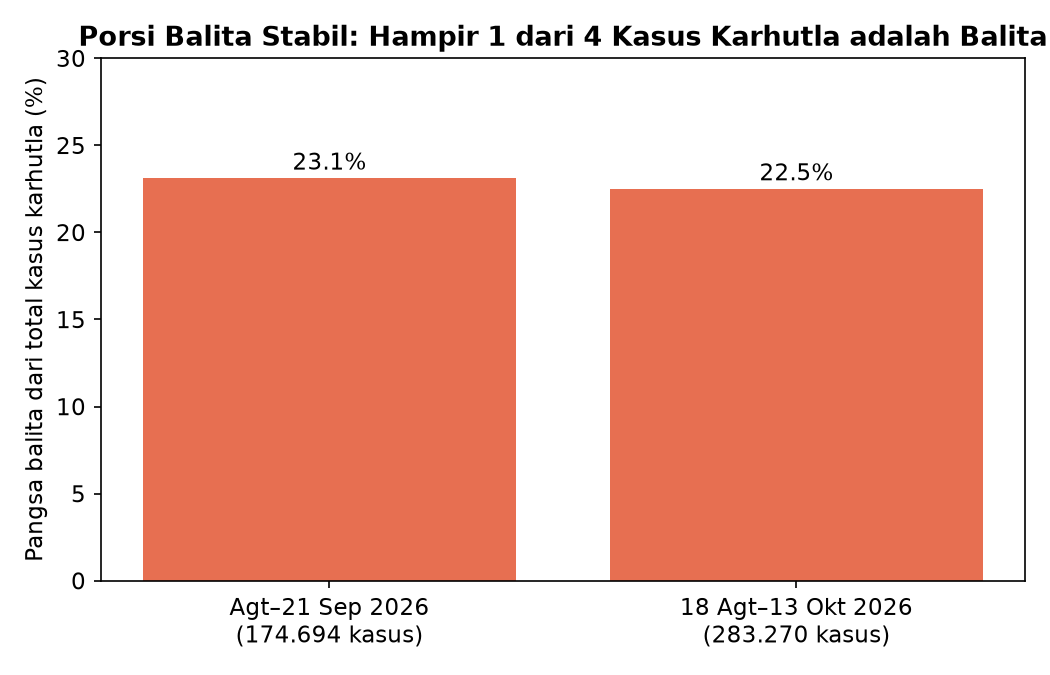

In [9]:
print(q("SELECT tanggal, CAST(kasus_kumulatif AS INTEGER) AS kumulatif FROM karhutla_series ORDER BY tanggal").to_string(index=False))
print("Faktor pertumbuhan 27 Agt -> 13 Okt:", q("SELECT ROUND(283270.0/13449, 1) AS x").iloc[0, 0], "kali lipat")
display(Image("charts/06_karhutla_pertumbuhan.png"))
display(Image("charts/10_balita_stabil.png"))


## I. Kualitas udara: 10 wilayah terburuk jauh di atas ambang berbahaya

Pada 12 Oktober 2026 pukul 15:00 WIB, konsentrasi PM2,5 di 10 wilayah terburuk
berkisar **507–1.837** — semuanya jauh di atas ambang ISPU "berbahaya" (>300).
Barito Kuala (1.837) mencapai **6,1 kali** ambang berbahaya. Dari 10 wilayah
terburuk, **7 berada di Kalimantan Tengah**. Kemenkes juga mencatat 12 kabupaten/kota
berkategori berbahaya dan 9 wilayah berkategori sangat tidak sehat.


                   wilayah           provinsi  pm25
              Barito Kuala Kalimantan Selatan  1837
                    Kapuas  Kalimantan Tengah  1681
Palangka Raya (Jekan Raya)  Kalimantan Tengah  1301
                  Katingan  Kalimantan Tengah  1214
       Hulu Sungai Selatan Kalimantan Selatan   921
                Gunung Mas  Kalimantan Tengah   674
   Barito Selatan (Sanggu)  Kalimantan Tengah   592
               Murung Raya  Kalimantan Tengah   577
        Kotawaringin Timur  Kalimantan Tengah   568
               Muaro Jambi              Jambi   507
Wilayah PM2,5 > 1.000: 4
Rasio Barito Kuala terhadap ambang berbahaya: 6.1 kali lipat


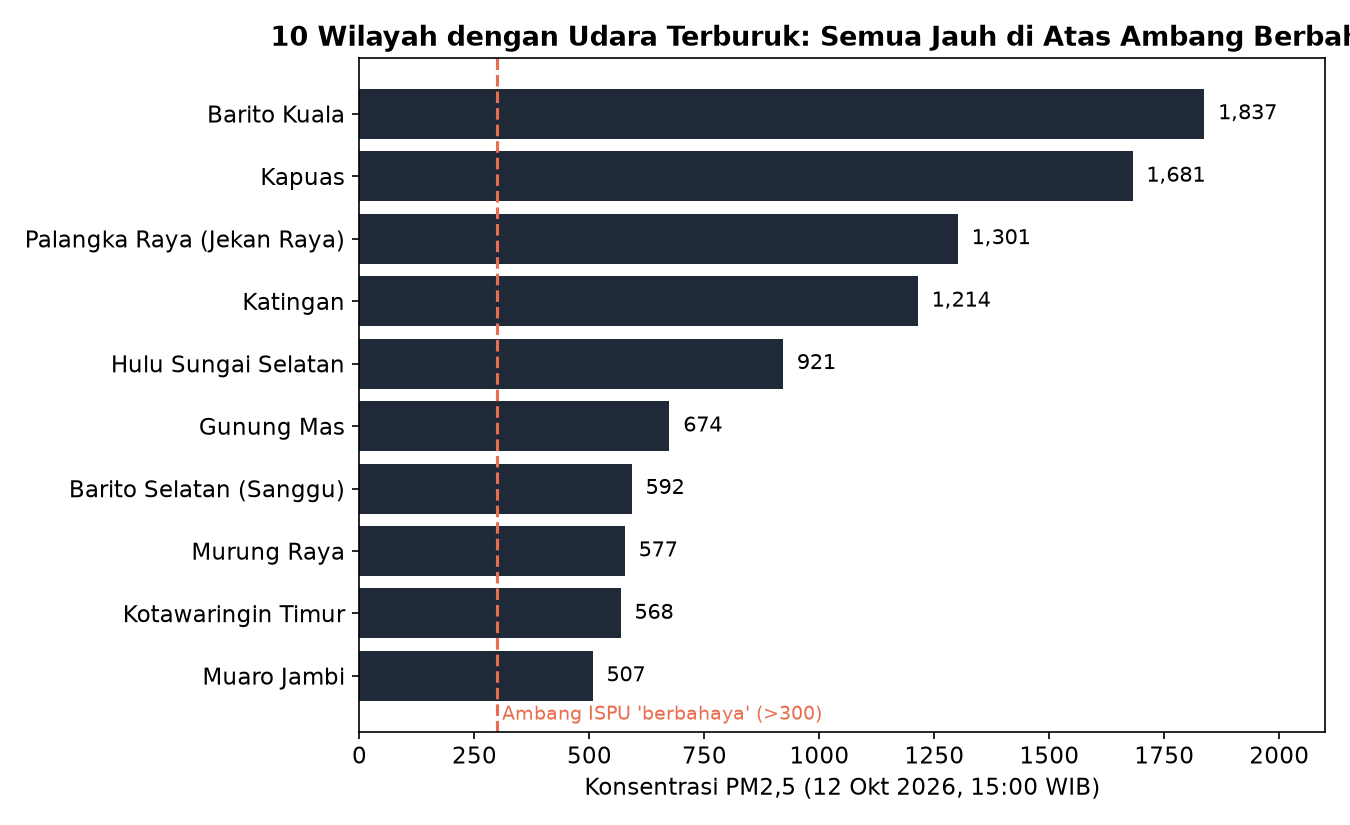

In [10]:
print(q("SELECT wilayah, provinsi, CAST(pm25_12okt2026_1500wib AS INTEGER) AS pm25 FROM ispu_wilayah ORDER BY pm25 DESC").to_string(index=False))
print("Wilayah PM2,5 > 1.000:", q("SELECT COUNT(*) AS n FROM ispu_wilayah WHERE CAST(pm25_12okt2026_1500wib AS INTEGER) > 1000").iloc[0, 0])
print("Rasio Barito Kuala terhadap ambang berbahaya:", q("SELECT ROUND(1837.0/300, 1) AS x").iloc[0, 0], "kali lipat")
display(Image("charts/07_ispu.png"))


## J. Studi kota: Jakarta

Jakarta mencatat **1.966.308 kasus ISPA pada Januari–Oktober 2025** dan 2,5 juta
kasus pada Januari–November 2025 (Dinkes DKI). Pada September 2026 Dinkes DKI
mencatat kenaikan musiman **+15,7%** (data puskesmas), namun belum melihat lonjakan
signifikan pada kunjungan rumah sakit (SIRS Online). Pola bulanan 2023 menunjukkan
kasus berkisar 99.130–119.734 per bulan (rata-rata 106.382), dengan puncak Maret
(119.734, +20,8% dibanding Mei yang terendah).


 rata_rata   min   maks
  106382.0 99130 119734
Total Jan-Jun 2023: 638291


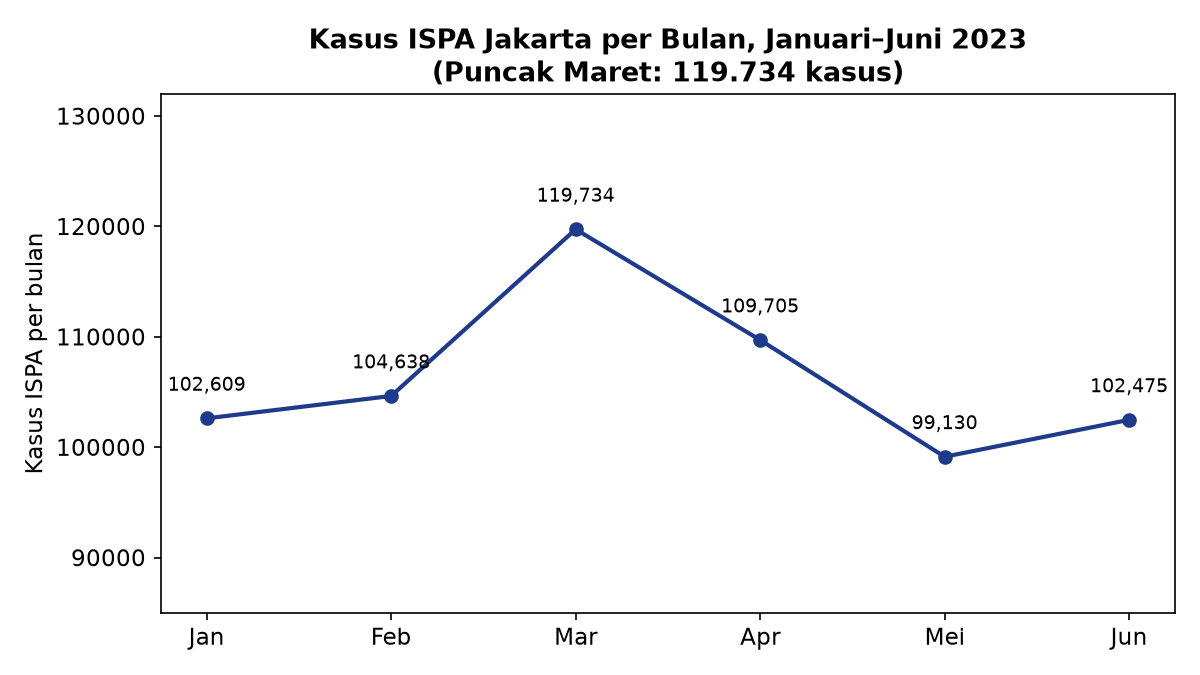

In [11]:
print(q("SELECT ROUND(AVG(CAST(kasus_ispa_jakarta_2023 AS INTEGER)), 0) AS rata_rata, MIN(CAST(kasus_ispa_jakarta_2023 AS INTEGER)) AS min, MAX(CAST(kasus_ispa_jakarta_2023 AS INTEGER)) AS maks FROM jakarta_bulanan").to_string(index=False))
print("Total Jan-Jun 2023:", q("SELECT SUM(CAST(kasus_ispa_jakarta_2023 AS INTEGER)) AS t FROM jakarta_bulanan").iloc[0, 0])
display(Image("charts/08_jakarta_bulanan.png"))


## K. Temuan kunci

| # | Temuan | Angka |
|---|---|---|
| 1 | Laporan ISPA nasional 2026 (SKDR, s.d. minggu ke-38) | 14.088.945 laporan |
| 2 | Laporan mingguan naik awal → puncak kemarau | >400 ribu → ~420 ribu (+5,0%) |
| 3 | 10 provinsi teratas = 74,7% laporan nasional; 4 teratas = 55,8% | 10.530.385 laporan |
| 4 | Beban per kapita tertinggi: DKI Jakarta | 150,0 per 1.000 penduduk |
| 5 | Laporan top-10 dari Pulau Jawa | 86,3% |
| 6 | Kasus ISPA karhutla (18 Agt–13 Okt 2026, 63 kab/kota) | 283.270 kasus |
| 7 | Balita di seri karhutla | 63.711 kasus (22,5%) |
| 8 | Kalsel + Sumsel = 52,6% kasus karhutla | 74.636 + 74.458 |
| 9 | Pertumbuhan kumulatif karhutla 27 Agt → 13 Okt | 21,1 kali lipat |
| 10 | PM2,5 tertinggi (Barito Kuala, 12 Okt 2026) | 1.837 (6,1x ambang berbahaya) |
| 11 | Jakarta Jan–Okt 2025 | 1.966.308 kasus |

## L. Keterbatasan — baca sebelum mengutip

- **Laporan bukan orang unik.** Angka SKDR menghitung laporan/kunjungan; satu
  orang yang berobat berulang bisa tercatat lebih dari sekali.
- **Cakupan pelaporan tidak merata.** Provinsi dengan fasilitas kesehatan lebih
  banyak cenderung mencatat lebih banyak kasus.
- **Analisis ekologis.** Korelasi tingkat provinsi (mis. wilayah ISPU buruk dan
  kasus ISPA tinggi) tidak membuktikan sebab-akibat pada level individu.
  Kemenkes sendiri menekankan ISPA juga dipengaruhi virus, bakteri, cuaca,
  mobilitas, dan faktor lingkungan lain.
- **Angka peringkat 5–10 SKDR dibaca dari grafik** (dibulatkan), bukan angka eksak.
- **Seri karhutla hanya mencakup 63 kabupaten/kota terdampak**, bukan seluruh
  provinsi tersebut, dan tidak boleh dijumlahkan ke total nasional.
- **Populasi** memakai satu vintage (BPS 2026); tiga provinsi dikeluarkan dari
  peringkat per kapita karena tidak ada angka populasi satu vintage yang
  terverifikasi.

## M. Rekomendasi

1. **Prioritaskan perlindungan balita di wilayah karhutla.** Hampir 1 dari 4
   kasus karhutla adalah balita — masker anak, pembelajaran jarak jauh saat ISPU
   berbahaya, dan posko kesehatan di 63 kabupaten/kota terdampak.
2. **Fokus pada Kalsel dan Sumsel.** Dua provinsi ini menanggung 52,6% kasus
   karhutla — distribusi masker (2,8 juta sudah disalurkan) dan 2.106 tenaga
   kesehatan perlu dipertahankan di sana.
3. **Perhatikan Jakarta secara khusus.** Beban per kapita Jakarta (150,0 per
   1.000) jauh di atas provinsi lain — surveilans puskesmas dan kesiapan RS
   perlu diperkuat pada puncak musim kemarau.
4. **Perbaiki transparansi data.** Publikasikan tabel provinsi lengkap dan
   deret mingguan SKDR dalam format terbuka agar analisis seperti ini tidak
   perlu mengompilasi dari grafik dan rilis pers.
5. **Jangan tunggu puncak kemarau.** Laporan mingguan sudah di atas 400 ribu
   sejak minggu ke-27 — pemantauan ISPU dan edukasi PHBS perlu dimulai sebelum
   musim kemarau, bukan setelah kasus meledak.

## Sumber

Seluruh sumber, tanggal, dan catatan per angka: `data/SOURCES.md`.
Sumber utama: Kemenkes (Situation Report M39-2026; rilis pers via Dir. Kesehatan
Lingkungan), SKDR, ISPU KemenLH, Dinkes DKI Jakarta, BPS (Statistik Indonesia 2026).
